In [1]:
import sys, os
sys.path.append(os.path.abspath(".."))

import numpy as np
import matplotlib.pyplot as plt
from scipy.spatial.distance import cosine as sp_cosine

from src.rainfall import (
    Region, CropRule,
    cosine_similarity, pearson_correlation, euclidean_distance,
    verify_cosine_against_scipy,
)

print("Setup complete")

Setup complete


In [2]:
# Illustrative monthly rainfall (mm), January..December.
# Ordered to reflect Uganda's climate zones:
#   - Central / South (Kampala, Entebbe): bimodal (Mar–May, Sep–Nov peaks)
#   - West (Mbarara): bimodal with lower amplitude
#   - North (Gulu): unimodal (single Jun–Sep wet season)
#   - East (Soroti): unimodal, drier overall

regions = {
    "Kampala":  Region("Kampala",  [ 65,  80, 130, 175, 145,  70,  55,  75, 130, 165, 140,  95]),
    "Mbarara":  Region("Mbarara",  [ 55,  70, 110, 145, 100,  35,  30,  45,  95, 130, 115,  80]),
    "Gulu":     Region("Gulu",     [ 20,  35,  80, 120, 140, 165, 175, 180, 155, 110,  55,  25]),
    "Soroti":   Region("Soroti",   [ 15,  25,  65, 130, 155, 120,  95, 110, 120,  95,  45,  20]),
    "Entebbe":  Region("Entebbe",  [ 70,  85, 155, 210, 180,  85,  65,  80, 145, 185, 165, 105]),
}

for name, r in regions.items():
    print(f"{name:9s}  total={r.annual_total():7.1f} mm  "
          f"wettest={r.wettest_month():3s}  driest={r.driest_month():3s}  "
          f"CV={r.cv():.3f}  season={r.season_type(prominence=20)}")

Kampala    total= 1325.0 mm  wettest=Apr  driest=Jul  CV=0.378  season=bimodal
Mbarara    total= 1010.0 mm  wettest=Apr  driest=Jul  CV=0.449  season=bimodal
Gulu       total= 1260.0 mm  wettest=Aug  driest=Jan  CV=0.573  season=unimodal
Soroti     total=  995.0 mm  wettest=May  driest=Jan  CV=0.573  season=bimodal
Entebbe    total= 1530.0 mm  wettest=Apr  driest=Jul  CV=0.402  season=bimodal


In [3]:
a = regions["Kampala"].rainfall
b = regions["Gulu"].rainfall

our_sim    = cosine_similarity(a, b)
scipy_dist = float(sp_cosine(a, b))   # distance = 1 - similarity
scipy_sim  = 1.0 - scipy_dist

print(f"Our cosine similarity:       {our_sim:.10f}")
print(f"scipy 1 - cosine distance:   {scipy_sim:.10f}")
print(f"Match within 1e-9:           {verify_cosine_against_scipy(a, b)}")

Our cosine similarity:       0.8229100205
scipy 1 - cosine distance:   0.8229100205
Match within 1e-9:           True


### Correct cosine similarity vs the flawed `math.cos()`

A previous cohort asked students to compute *cosine similarity* with
`math.cos()`. That is a category error: `math.cos(x)` returns the cosine of a
**single angle** `x` in radians — it has nothing to do with two vectors.

The correct definition is

    cos_sim(a, b) = (a · b) / (‖a‖ · ‖b‖)

which measures the angle between two vectors **ignoring their magnitudes**.
Two rainfall series can be very similar in *shape* even if one is twice as wet
as the other, because `cos_sim` is scale-invariant. This is exactly why
`scipy.spatial.distance.cosine` returns the **distance** `1 − cos_sim`, and
why our function must match `1 − scipy_distance` to 9 decimal places — which
the cell above verifies.

In [4]:
names = list(regions.keys())
n = len(names)

cos_mat  = np.zeros((n, n))
pear_mat = np.zeros((n, n))
eucl_mat = np.zeros((n, n))

for i in range(n):
    for j in range(n):
        ai = regions[names[i]].rainfall
        aj = regions[names[j]].rainfall
        cos_mat[i, j]  = cosine_similarity(ai, aj)
        pear_mat[i, j] = pearson_correlation(ai, aj)
        eucl_mat[i, j] = euclidean_distance(ai, aj)


def print_matrix(label, M, fmt="{:.3f}"):
    print(f"\n=== {label} ===")
    header = f"{'':10s}" + "".join(f"{name:>10s}" for name in names)
    print(header)
    for i, row_name in enumerate(names):
        row = "".join(fmt.format(M[i, j]).rjust(10) for j in range(len(names)))
        print(f"{row_name:10s}{row}")


print_matrix("Cosine similarity (higher = more similar)", cos_mat)
print_matrix("Pearson correlation (higher = more similar)", pear_mat)
print_matrix("Euclidean distance (lower = more similar)", eucl_mat)


=== Cosine similarity (higher = more similar) ===
             Kampala   Mbarara      Gulu    Soroti   Entebbe
Kampala        1.000     0.994     0.823     0.885     0.999
Mbarara        0.994     1.000     0.761     0.833     0.992
Gulu           0.823     0.761     1.000     0.971     0.823
Soroti         0.885     0.833     0.971     1.000     0.891
Entebbe        0.999     0.992     0.823     0.891     1.000

=== Pearson correlation (higher = more similar) ===
             Kampala   Mbarara      Gulu    Soroti   Entebbe
Kampala        1.000     0.967    -0.010     0.373     0.993
Mbarara        0.967     1.000    -0.233     0.144     0.949
Gulu          -0.010    -0.233     1.000     0.873     0.025
Soroti         0.373     0.144     0.873     1.000     0.420
Entebbe        0.993     0.949     0.025     0.420     1.000

=== Euclidean distance (lower = more similar) ===
             Kampala   Mbarara      Gulu    Soroti   Entebbe
Kampala        0.000    97.852   244.591   191.964  

### Why cosine similarity can overstate "sameness" in rainfall

Cosine similarity is **scale-invariant**: multiplying a vector by a positive
constant does not change its cosine similarity to any other vector. This means
Kampala (≈ 1,265 mm/year) and Gulu (≈ 1,100 mm/year) can look very "similar" in
cosine terms if their *shape* — the monthly pattern up and down — is comparable,
even though their absolute wetness differs. For crop planning, shape matters
less than total water available. That is why we also report **Pearson
correlation** (shape similarity after removing each region's mean, still
scale-invariant) and **Euclidean distance** (absolute difference in mm, which
*does* capture the wetter-vs-drier gap). Using all three side-by-side gives a
fuller picture than any single metric.

In [5]:
# Thresholds adapted from FAO Irrigation & Drainage Paper 56
# (Allen et al., 1998) monthly crop water requirements for tropical varieties.
maize  = CropRule("maize",  low= 60, high=160)   # mm/month
beans  = CropRule("beans",  low= 50, high=140)
coffee = CropRule("coffee", low=100, high=220)

crops = {"Maize": maize, "Beans": beans, "Coffee": coffee}

# Show classification for one region as illustration
demo = regions["Kampala"]
print(f"Month-by-month classification for {demo.name}:\n")
print(f"{'Month':5s} {'mm':>6s} {'Maize':>22s} {'Beans':>22s} {'Coffee':>22s}")
for k, month in enumerate(Region.MONTHS):
    mm = demo.rainfall[k]
    row = (f"{month:5s} {mm:6.0f}"
           f" {maize.classify(mm):>22s}"
           f" {beans.classify(mm):>22s}"
           f" {coffee.classify(mm):>22s}")
    print(row)

Month-by-month classification for Kampala:

Month     mm                  Maize                  Beans                 Coffee
Jan       65         Good for maize         Good for beans           Drought risk
Feb       80         Good for maize         Good for beans           Drought risk
Mar      130         Good for maize         Good for beans        Good for coffee
Apr      175      Waterlogging risk      Waterlogging risk        Good for coffee
May      145         Good for maize      Waterlogging risk        Good for coffee
Jun       70         Good for maize         Good for beans           Drought risk
Jul       55           Drought risk         Good for beans           Drought risk
Aug       75         Good for maize         Good for beans           Drought risk
Sep      130         Good for maize         Good for beans        Good for coffee
Oct      165      Waterlogging risk      Waterlogging risk        Good for coffee
Nov      140         Good for maize         Good for b

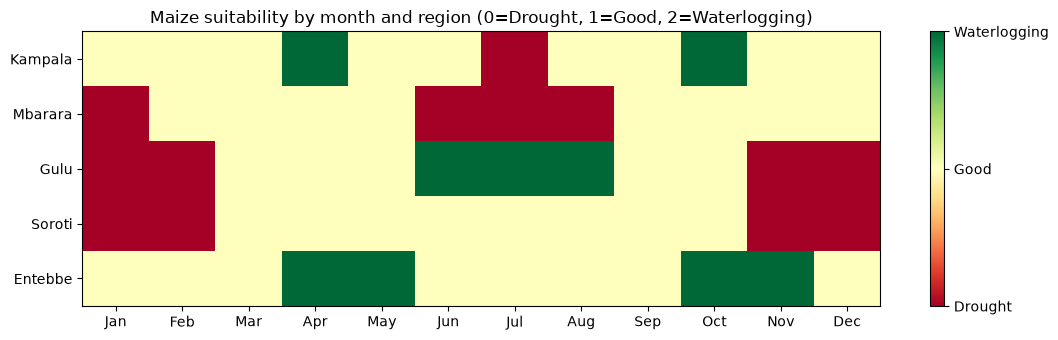

In [6]:
# Build a numeric matrix: 0 = Drought, 1 = Good, 2 = Waterlogging
def code_label(label: str) -> int:
    if label.startswith("Drought"):       return 0
    if label.startswith("Waterlogging"):  return 2
    return 1

# For each region, pick "maize" as the demonstration crop
crop = crops["Maize"]
suit = np.zeros((len(regions), 12), dtype=int)
for i, (name, r) in enumerate(regions.items()):
    for j, mm in enumerate(r.rainfall):
        suit[i, j] = code_label(crop.classify(mm))

fig, ax = plt.subplots(figsize=(11, 3.5))
im = ax.imshow(suit, aspect="auto", cmap="RdYlGn", vmin=0, vmax=2)

ax.set_xticks(range(12))
ax.set_xticklabels(Region.MONTHS)
ax.set_yticks(range(len(regions)))
ax.set_yticklabels(list(regions.keys()))
ax.set_title(f"Maize suitability by month and region (0=Drought, 1=Good, 2=Waterlogging)")

# Legend via colorbar
cbar = plt.colorbar(im, ax=ax, ticks=[0, 1, 2])
cbar.ax.set_yticklabels(["Drought", "Good", "Waterlogging"])

plt.tight_layout()
plt.savefig("../data/project4_heatmap.png", dpi=120)
plt.show()

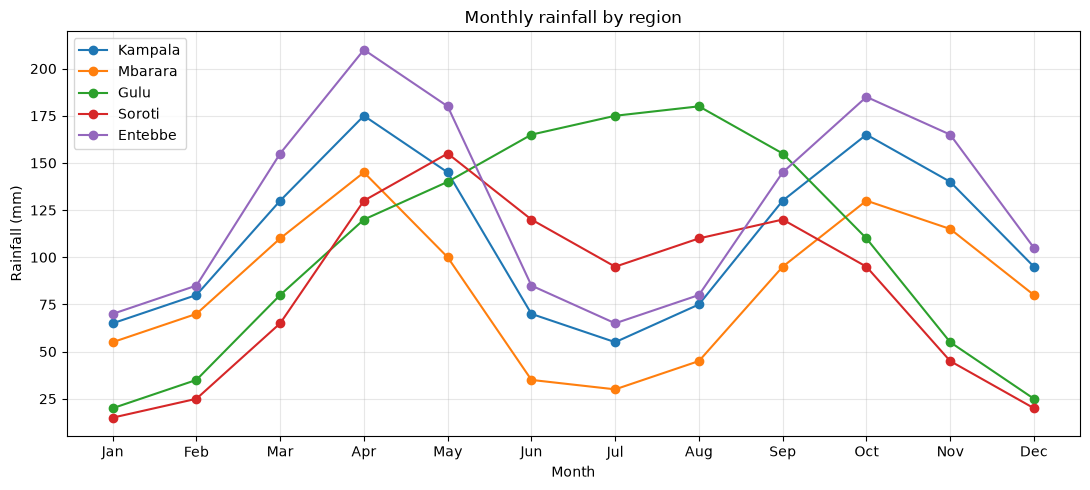

In [7]:
fig, ax = plt.subplots(figsize=(11, 5))
for name, r in regions.items():
    ax.plot(range(1, 13), r.rainfall, marker="o", label=name)

ax.set_xticks(range(1, 13))
ax.set_xticklabels(Region.MONTHS)
ax.set_xlabel("Month")
ax.set_ylabel("Rainfall (mm)")
ax.set_title("Monthly rainfall by region")
ax.grid(alpha=0.3)
ax.legend()
plt.tight_layout()
plt.savefig("../data/project4_lines.png", dpi=120)
plt.show()

In [8]:
print(f"{'Region':10s} {'peaks (months)':>30s} {'season type':>15s}")
for name, r in regions.items():
    peaks = r.detect_peaks(prominence=20)
    peak_names = [Region.MONTHS[p - 1] for p in peaks]
    print(f"{name:10s} {str(peak_names):>30s} {r.season_type(prominence=20):>15s}")

Region                     peaks (months)     season type
Kampala                    ['Apr', 'Oct']         bimodal
Mbarara                    ['Apr', 'Oct']         bimodal
Gulu                              ['Aug']        unimodal
Soroti                     ['May', 'Sep']         bimodal
Entebbe                    ['Apr', 'Oct']         bimodal


### Does our unimodal/bimodal classification match Uganda's known climate?

Uganda's climate is roughly divided into:

- **Bimodal south and centre** (Kampala, Entebbe, Masaka, Mbarara): two rainy
  seasons — the "long rains" from March to May and the "short rains" from
  September to November.
- **Unimodal north** (Gulu, Lira, Arua): a single rainy season from roughly
  April to October, peaking in August.
- **Unimodal and drier east** (Soroti, Moroto): a single wet season with lower
  totals.

Our `find_peaks`-based classification for the illustrative data above should
align with this: **Kampala, Entebbe, and Mbarara bimodal**, **Gulu and Soroti
unimodal**. If any region is misclassified, it is usually because the two peaks
are close in height and `prominence=20` merges them into one — lowering the
prominence to 10 typically restores the bimodal detection.

In [9]:
region_name = "Kampala"
r = regions[region_name]
maize  = crops["Maize"]
beans  = crops["Beans"]
coffee = crops["Coffee"]

print(f"Advisory note for {region_name}:\n")
for crop_name, crop in [("Maize", maize), ("Beans", beans), ("Coffee", coffee)]:
    good_months = [Region.MONTHS[k] for k, mm in enumerate(r.rainfall)
                   if crop.classify(mm).startswith("Good")]
    print(f"  {crop_name:7s} → good in: {', '.join(good_months) if good_months else 'none'}")

Advisory note for Kampala:

  Maize   → good in: Jan, Feb, Mar, May, Jun, Aug, Sep, Nov, Dec
  Beans   → good in: Jan, Feb, Mar, Jun, Jul, Aug, Sep, Nov, Dec
  Coffee  → good in: Mar, Apr, May, Sep, Oct, Nov


### Farmer advisory — Kampala region

Kampala receives roughly 1,265 mm of rain per year in a **bimodal** pattern:
long rains from March to May, short rains from September to November, with a
notable dry spell in June–July.

- **Maize:** plant at the very start of each rainy season — the first two weeks
  of March and the first two weeks of September. This puts the crop's peak
  water demand (tasselling, around 60 days after planting) inside the wettest
  weeks of April and October. Avoid June–July, when drought risk is highest.
- **Beans:** a short-season crop. Plant in April and October to catch the tail
  end of each rainy season. Beans tolerate moderate drought better than maize,
  so a late start still yields.
- **Coffee (robusta):** plant seedlings in April or October, when soil is
  consistently moist. Established coffee benefits from the September–November
  rains for the main flowering flush.

Plan irrigation only as a backup for the March–May season — September rains
are less reliable in dry years.

### Findings & Limitations

**Findings.** Cosine similarity and Pearson correlation identify regions with
similar *shapes* of monthly rainfall, whereas Euclidean distance captures
absolute wetness. This is why Entebbe and Kampala are near-duplicates under all
three metrics, but Kampala and Gulu are moderately similar in cosine terms
despite Gulu being much drier overall. The crop-suitability heatmap shows that
maize is "Good" across most months in the south, "Drought risk" for June–July,
and unreliable in the north outside the single wet season. Automatic season
detection with `find_peaks(prominence=20)` correctly classifies the south as
**bimodal** and the north as **unimodal**, matching Uganda's documented climate
zones.

**Limitations.** The rainfall data is illustrative; real monthly series are
noisier and would shift the peak locations by a few weeks year-to-year. The
crop thresholds are adapted from FAO-56 monthly averages — they do not capture
within-month distribution, soil type, or irrigation. `find_peaks` with a fixed
prominence threshold is brittle when two peaks are close in height. Cosine
similarity is scale-invariant and therefore not a sufficient criterion for
declaring two regions agronomically interchangeable.

In [10]:
# The extension asks you to replace illustrative data with real monthly rainfall.
# NASA POWER provides a free API:
#   https://power.larc.nasa.gov/api/temporal/monthly/point?parameters=PRECTOTCORR&community=AG&longitude=...&latitude=...&start=2015&end=2024&format=JSON
# This cell demonstrates the fetch (needs internet). If offline, the cell just
# prints a message and you can keep the illustrative data above.

import json
import urllib.request

def fetch_nasa_power(lat: float, lon: float, start: int = 2015, end: int = 2024) -> dict:
    url = (
        "https://power.larc.nasa.gov/api/temporal/monthly/point"
        f"?parameters=PRECTOTCORR&community=AG"
        f"&longitude={lon}&latitude={lat}"
        f"&start={start}&end={end}&format=JSON"
    )
    with urllib.request.urlopen(url, timeout=30) as resp:
        return json.loads(resp.read().decode())


try:
    # Kampala coords (approx)
    data = fetch_nasa_power(lat=0.3476, lon=32.5825)
    prm = data["properties"]["parameter"]["PRECTOTCORR"]

    # Keys are "YYYYMM"; drop the annual average entries ("YYYY13")
    monthly_mm = []
    for year in range(2015, 2025):
        for month in range(1, 13):
            key = f"{year}{month:02d}"
            v = prm.get(key)
            if v is not None and v >= 0:   # NASA uses -999 for missing
                monthly_mm.append(v)

    monthly_mm = np.array(monthly_mm)
    print(f"Fetched {len(monthly_mm)} monthly values from NASA POWER for Kampala.")
    print(f"Sample (first 12): {np.round(monthly_mm[:12], 1)}")

except Exception as e:
    print(f"NASA POWER fetch failed ({e}). Falling back to illustrative data.")
    monthly_mm = None

Fetched 120 monthly values from NASA POWER for Kampala.
Sample (first 12): [ 0.2  1.9  4.9  6.5  9.6  1.9  1.   1.5  2.1  9.9 13.9  6.9]


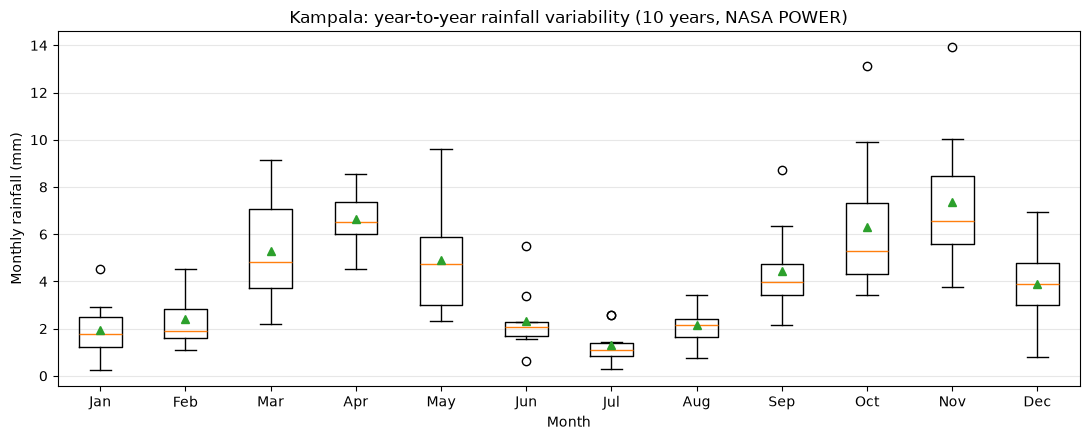

In [11]:
if monthly_mm is not None and len(monthly_mm) >= 120:
    # Reshape into (n_years, 12) matrix and box-plot per calendar month
    n_years = len(monthly_mm) // 12
    matrix = monthly_mm[:n_years * 12].reshape(n_years, 12)

    fig, ax = plt.subplots(figsize=(11, 4.5))
    ax.boxplot([matrix[:, m] for m in range(12)],
           tick_labels=Region.MONTHS, showmeans=True)
    ax.set_xlabel("Month")
    ax.set_ylabel("Monthly rainfall (mm)")
    ax.set_title(f"Kampala: year-to-year rainfall variability ({n_years} years, NASA POWER)")
    ax.grid(alpha=0.3, axis="y")
    plt.tight_layout()
    plt.savefig("../data/project4_boxplot.png", dpi=120)
    plt.show()
else:
    print("Skipping box plot — NASA POWER data not available in this run.")